In [1]:
from pathlib import Path
from collections import Counter
import shutil
import pandas as pd
import yaml

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

AUDIT_PATH = ROOT / "data/processed/detection_annotation_audit.csv"

CLEAN_DIR = ROOT / "data/processed/detection_4class"
BALANCED_DIR = ROOT / "data/processed/detection_4class_balanced"

CLASSES = {
    0: "Glioma",
    1: "Meningioma",
    2: "No Tumor",
    3: "Pituitary",
}

NAME_TO_ID = {name: idx for idx, name in CLASSES.items()}
SEED = 42

audit = pd.read_csv(AUDIT_PATH)

accepted = audit[
    audit["status"].isin(["valid_tumor", "valid_negative"])
].copy()

assert accepted["hash"].is_unique

print("Accepted images:", len(accepted))
print(pd.crosstab(accepted["split"], accepted["class_name"]))

Accepted images: 3688
class_name  Glioma  Meningioma  No Tumor  Pituitary
split                                              
test           161         158        90        154
train          725         710       420        719
val            155         154        89        153


In [2]:
records = []
skipped = []

for row in accepted.itertuples(index=False):
    src = ROOT / row.source_image
    src_label = (
        src.parent.parent / "labels" / f"{src.stem}.txt"
    )

    lines = [
        line.strip()
        for line in src_label.read_text(encoding="utf-8-sig").splitlines()
        if line.strip()
    ]

    # Four-class detection needs actual boxes.
    if not lines:
        skipped.append(row.source_image)
        continue

    expected_id = NAME_TO_ID[row.class_name]

    # Reject unexpected classes rather than silently rewriting them.
    assert all(
        len(line.split()) == 5
        and int(line.split()[0]) == expected_id
        for line in lines
    ), f"Unexpected annotation: {src_label}"

    filename = f"{row.hash}{src.suffix.lower()}"

    image_dest = CLEAN_DIR / "images" / row.split / filename
    label_dest = CLEAN_DIR / "labels" / row.split / f"{row.hash}.txt"

    image_dest.parent.mkdir(parents=True, exist_ok=True)
    label_dest.parent.mkdir(parents=True, exist_ok=True)

    shutil.copy2(src, image_dest)
    label_dest.write_text("\n".join(lines) + "\n")

    records.append({
        "hash": row.hash,
        "split": row.split,
        "class_name": row.class_name,
        "filename": filename,
        "box_count": len(lines),
    })

clean_df = pd.DataFrame(records)

def write_yaml(directory):
    configuration = {
        "path": str(directory.resolve()),
        "train": "images/train",
        "val": "images/val",
        "test": "images/test",
        "names": CLASSES,
    }

    with open(directory / "data.yaml", "w") as f:
        yaml.safe_dump(configuration, f, sort_keys=False)

write_yaml(CLEAN_DIR)
clean_df.to_csv(CLEAN_DIR / "manifest.csv", index=False)

# Validate resulting structure.
for split in ["train", "val", "test"]:
    subset = clean_df[clean_df["split"] == split]

    assert len(list((CLEAN_DIR / "images" / split).iterdir())) == len(subset)
    assert len(list((CLEAN_DIR / "labels" / split).glob("*.txt"))) == len(subset)

print("Four-class dataset created:", len(clean_df))
print("Skipped empty annotations:", len(skipped))
print(pd.crosstab(clean_df["split"], clean_df["class_name"]))
print("YAML:", CLEAN_DIR / "data.yaml")

Four-class dataset created: 3688
Skipped empty annotations: 0
class_name  Glioma  Meningioma  No Tumor  Pituitary
split                                              
test           161         158        90        154
train          725         710       420        719
val            155         154        89        153
YAML: /home/houssam/Desktop/Briefs/Brief 5/data/processed/detection_4class/data.yaml


In [3]:
train_df = clean_df[clean_df["split"] == "train"].copy()
counts = train_df["class_name"].value_counts()

glioma_count = counts["Glioma"]

target = min(
    counts["Glioma"],
    counts["Meningioma"],
    counts["Pituitary"],
)

print("Original counts:")
print(counts)

print("\nGlioma count:", glioma_count)
print("Balancing target:", target)

balanced_records = []

for class_id, class_name in CLASSES.items():
    group = train_df[
        train_df["class_name"] == class_name
    ]

    if len(group) >= target:
        selected = group.sample(
            n=target,
            replace=False,
            random_state=SEED,
        )
    else:
        # Keep all available examples, then repeat a random subset.
        extra = group.sample(
            n=target - len(group),
            replace=True,
            random_state=SEED,
        )
        selected = pd.concat([group, extra], ignore_index=True)

    for i, row in enumerate(selected.itertuples(index=False)):
        src_img = CLEAN_DIR / "images/train" / row.filename
        src_label = (
            CLEAN_DIR / "labels/train" / f"{row.hash}.txt"
        )

        # Unique filenames allow repeated training examples.
        stem = f"{class_id}_{i:05d}_{row.hash}"
        new_filename = stem + Path(row.filename).suffix

        dst_img = BALANCED_DIR / "images/train" / new_filename
        dst_label = BALANCED_DIR / "labels/train" / f"{stem}.txt"

        dst_img.parent.mkdir(parents=True, exist_ok=True)
        dst_label.parent.mkdir(parents=True, exist_ok=True)

        shutil.copy2(src_img, dst_img)
        shutil.copy2(src_label, dst_label)

        balanced_records.append({
            "hash": row.hash,
            "split": "train",
            "class_name": class_name,
            "filename": new_filename,
        })

# Preserve validation and test without resampling.
for split in ["val", "test"]:
    for row in clean_df[
        clean_df["split"] == split
    ].itertuples(index=False):

        src_img = CLEAN_DIR / "images" / split / row.filename
        src_label = CLEAN_DIR / "labels" / split / f"{row.hash}.txt"

        dst_img = BALANCED_DIR / "images" / split / row.filename
        dst_label = BALANCED_DIR / "labels" / split / f"{row.hash}.txt"

        dst_img.parent.mkdir(parents=True, exist_ok=True)
        dst_label.parent.mkdir(parents=True, exist_ok=True)

        shutil.copy2(src_img, dst_img)
        shutil.copy2(src_label, dst_label)

        balanced_records.append({
            "hash": row.hash,
            "split": split,
            "class_name": row.class_name,
            "filename": row.filename,
        })

balanced_df = pd.DataFrame(balanced_records)

write_yaml(BALANCED_DIR)
balanced_df.to_csv(BALANCED_DIR / "manifest.csv", index=False)

assert balanced_df[
    balanced_df["split"] == "train"
]["class_name"].value_counts().nunique() == 1

print("\nBalanced dataset:")
print(pd.crosstab(
    balanced_df["split"],
    balanced_df["class_name"]
))

print("\nDataset ready:", BALANCED_DIR)

Original counts:
class_name
Glioma        725
Pituitary     719
Meningioma    710
No Tumor      420
Name: count, dtype: int64

Glioma count: 725
Balancing target: 710

Balanced dataset:
class_name  Glioma  Meningioma  No Tumor  Pituitary
split                                              
test           161         158        90        154
train          710         710       710        710
val            155         154        89        153

Dataset ready: /home/houssam/Desktop/Briefs/Brief 5/data/processed/detection_4class_balanced


In [4]:
from ultralytics import YOLO
import torch

assert torch.cuda.is_available(), "CUDA GPU not detected"

RUNS_DIR = ROOT / "models/detection_4class"

training_config = {
    "epochs": 60,
    "patience": 15,
    "imgsz": 640,
    "batch": 8,
    "device": 0,
    "workers": 2,
    "optimizer": "AdamW",
    "lr0": 5e-4,
    "lrf": 0.01,
    "cos_lr": True,
    "weight_decay": 0.0005,
    "warmup_epochs": 3.0,
    "box": 7.5,
    "cls": 0.5,
    "dfl": 1.5,
    "degrees": 10.0,
    "translate": 0.05,
    "scale": 0.10,
    "fliplr": 0.5,
    "flipud": 0.0,
    "hsv_h": 0.015,
    "hsv_s": 0.2,
    "hsv_v": 0.2,
    "mosaic": 0.5,
    "mixup": 0.0,
    "seed": SEED,
    "project": str(RUNS_DIR),
    "plots": True,
}

checkpoints = {}

for name, dataset in [
    ("yolov8n_4class_unbalanced", CLEAN_DIR),
    ("yolov8n_4class_balanced", BALANCED_DIR),
]:
    print(f"\nTRAINING: {name}")

    model = YOLO("yolov8n.pt")

    model.train(
        data=str(dataset / "data.yaml"),
        name=name,
        exist_ok=False,
        **training_config,
    )

    checkpoint = Path(model.trainer.save_dir) / "weights/best.pt"

    assert checkpoint.exists()
    checkpoints[name] = checkpoint

print("\nTraining finished.")
print(checkpoints)


TRAINING: yolov8n_4class_unbalanced
New https://pypi.org/project/ultralytics/8.4.190 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.189 🚀 Python-3.14.8 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5070 Laptop GPU, 7799MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/home/houssam/Desktop/Briefs/Brief 5/data/processed/detection_4class/data.yaml, degrees=10.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.2, hsv_v=0.2, imgsz=640, iou=0.7, kobj=1.0, lin

In [5]:
from ultralytics import YOLO
from pathlib import Path
import pandas as pd
import numpy as np
from IPython.display import display

models = {
    "Unbalanced": RUNS_DIR / "yolov8n_4class_unbalanced/weights/best.pt",
    "Balanced": RUNS_DIR / "yolov8n_4class_balanced/weights/best.pt",
}

results = []
class_results = []

for name, model_path in models.items():
    print(f"\n{'='*60}")
    print(f"EVALUATING: {name}")
    print(f"{'='*60}")

    model = YOLO(str(model_path))

    metrics = model.val(
        data=str(CLEAN_DIR / "data.yaml"),
        split="val",
        imgsz=640,
        batch=8,
        device=0,
        plots=True,
        project=str(RUNS_DIR / "evaluation"),
        name=name.lower(),
        exist_ok=True,
        verbose=False,
    )

    results.append({
        "Model": name,
        "Precision": metrics.box.mp,
        "Recall": metrics.box.mr,
        "mAP50": metrics.box.map50,
        "mAP50-95": metrics.box.map,
    })

    # Per-class metrics, indexed by YOLO's evaluated classes.
    for i, class_id in enumerate(metrics.box.ap_class_index):
        class_results.append({
            "Model": name,
            "Class": model.names[int(class_id)],
            "Precision": metrics.box.p[i],
            "Recall": metrics.box.r[i],
            "mAP50": metrics.box.ap50[i],
            "mAP50-95": metrics.box.ap[i],
        })

df_results = pd.DataFrame(results)
df_classes = pd.DataFrame(class_results)

print("\nOVERALL VALIDATION RESULTS")
display(
    df_results.style.format({
        "Precision": "{:.2%}",
        "Recall": "{:.2%}",
        "mAP50": "{:.2%}",
        "mAP50-95": "{:.2%}",
    })
)

print("\nPER-CLASS RESULTS")
display(
    df_classes.style.format({
        "Precision": "{:.2%}",
        "Recall": "{:.2%}",
        "mAP50": "{:.2%}",
        "mAP50-95": "{:.2%}",
    })
)

print("\nTUMOR-ONLY mAP50-95 (excluding No Tumor)")
tumor_only = (
    df_classes[df_classes["Class"] != "No Tumor"]
    .groupby("Model")["mAP50-95"]
    .mean()
)

display(tumor_only.to_frame("Tumor mAP50-95").style.format("{:.2%}"))

print("\nBEST MODEL BY FOUR-CLASS VALIDATION mAP50-95:")
best = df_results.loc[df_results["mAP50-95"].idxmax()]
print(f"{best['Model']}: {best['mAP50-95']:.2%}")


EVALUATING: Unbalanced
Ultralytics 8.4.189 🚀 Python-3.14.8 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5070 Laptop GPU, 7799MiB)
Model summary (fused): 73 layers, 3,133,436 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1990.8±1118.6 MB/s, size: 51.1 KB)
val: Scanning /home/houssam/Desktop/Briefs/Brief 5/data/processed/detection_4class/labels/val.cache... 551 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 551/551 192.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 69/69 6.3it/s 10.9s<0.1s
                   all        551        590      0.931      0.921      0.959      0.723
Speed: 0.5ms preprocess, 2.4ms inference, 0.0ms loss, 0.4ms postprocess per image
Results saved to /home/houssam/Desktop/Briefs/Brief 5/models/detection_4class/evaluation/unbalanced

EVALUATING: Balanced
Ultralytics 8.4.189 🚀 Python-3.14.8 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5070 Laptop 

,Model,Precision,Recall,mAP50,mAP50-95
0,Unbalanced,93.13%,92.09%,95.85%,72.35%
1,Balanced,94.98%,91.60%,96.28%,72.84%



PER-CLASS RESULTS


,Model,Class,Precision,Recall,mAP50,mAP50-95
0,Unbalanced,Glioma,87.31%,79.38%,88.71%,68.14%
1,Unbalanced,Meningioma,92.54%,96.20%,98.01%,77.91%
2,Unbalanced,No Tumor,99.36%,97.75%,99.38%,72.36%
3,Unbalanced,Pituitary,93.29%,95.01%,97.29%,70.97%
4,Balanced,Glioma,90.52%,78.74%,90.00%,66.65%
5,Balanced,Meningioma,96.08%,95.57%,98.05%,78.15%
6,Balanced,No Tumor,97.77%,98.59%,99.38%,77.27%
7,Balanced,Pituitary,95.56%,93.51%,97.69%,69.30%



TUMOR-ONLY mAP50-95 (excluding No Tumor)


,Tumor mAP50-95
Model,
Balanced,71.37%
Unbalanced,72.34%



BEST MODEL BY FOUR-CLASS VALIDATION mAP50-95:
Balanced: 72.84%


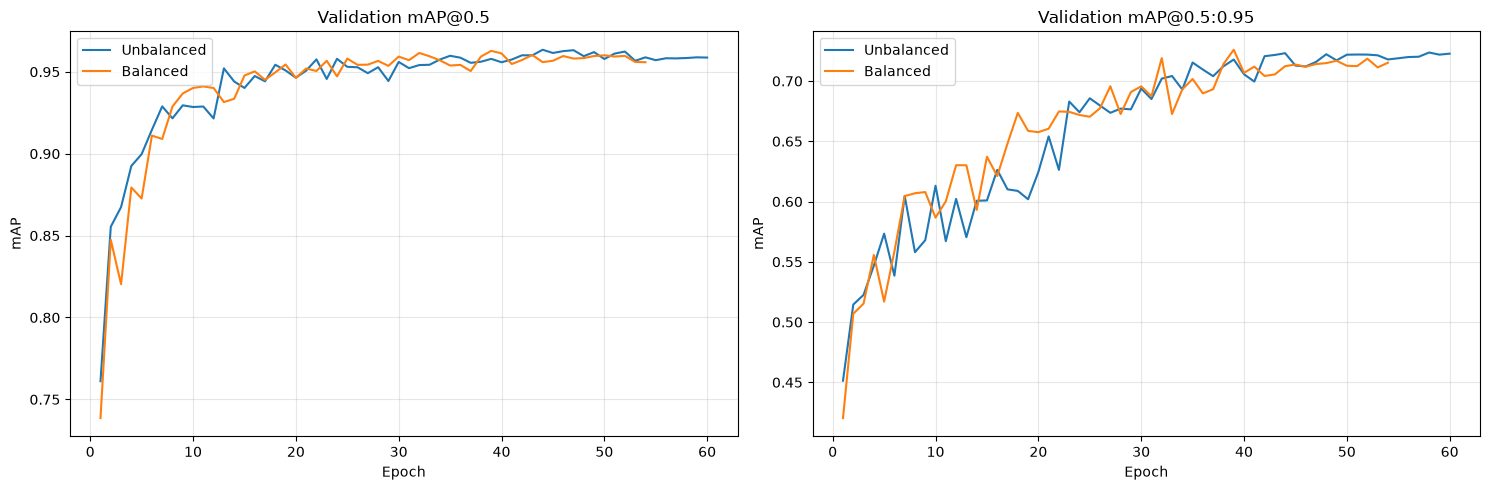

In [6]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for name, model_path in models.items():
    csv_path = model_path.parent.parent / "results.csv"

    df = pd.read_csv(csv_path)
    df.columns = df.columns.str.strip()

    axes[0].plot(
        df["epoch"],
        df["metrics/mAP50(B)"],
        label=name,
    )

    axes[1].plot(
        df["epoch"],
        df["metrics/mAP50-95(B)"],
        label=name,
    )

axes[0].set_title("Validation mAP@0.5")
axes[1].set_title("Validation mAP@0.5:0.95")

for ax in axes:
    ax.set_xlabel("Epoch")
    ax.set_ylabel("mAP")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

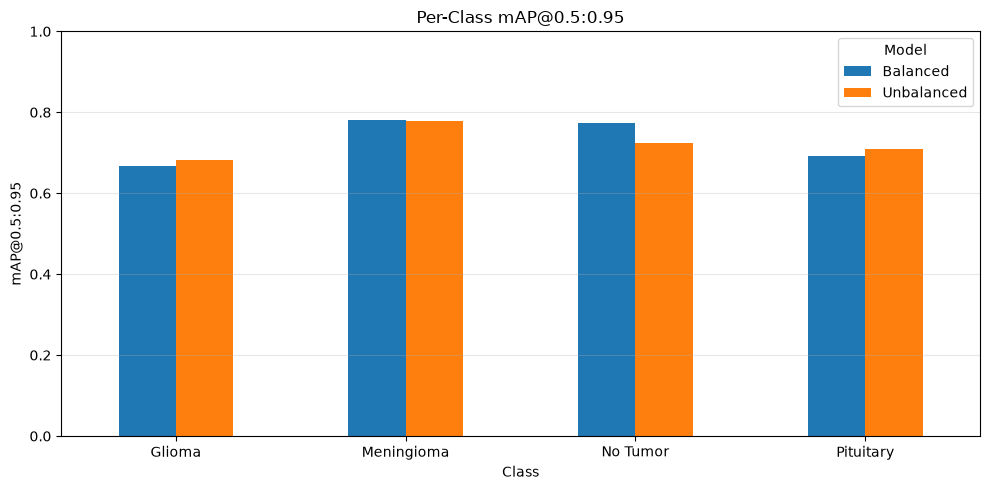

In [7]:
import matplotlib.pyplot as plt

comparison = df_classes.pivot(
    index="Class",
    columns="Model",
    values="mAP50-95",
)

ax = comparison.plot(
    kind="bar",
    figsize=(10, 5),
    rot=0,
)

ax.set_title("Per-Class mAP@0.5:0.95")
ax.set_ylabel("mAP@0.5:0.95")
ax.set_ylim(0, 1)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

,Boxes,Mean_Area,Median_Area,Min_Area,Max_Area
Class,,,,,
Glioma,843,0.0222,0.0179,0.0006,0.1043
Meningioma,726,0.0342,0.0266,0.0024,0.1839
No Tumor,420,0.6248,0.6117,0.1973,0.9910
Pituitary,774,0.0122,0.0101,0.0006,0.0671


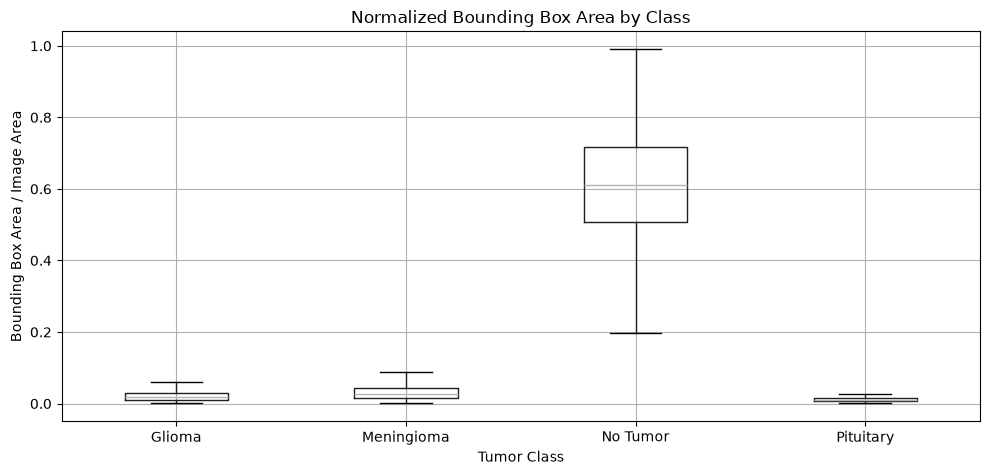

In [8]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

records = []

for class_id, class_name in CLASSES.items():
    subset = clean_df[
        (clean_df["split"] == "train") &
        (clean_df["class_name"] == class_name)
    ]

    for row in subset.itertuples(index=False):
        label_path = (
            CLEAN_DIR / "labels/train" / f"{row.hash}.txt"
        )

        for line in label_path.read_text().splitlines():
            values = line.strip().split()

            if len(values) != 5:
                continue

            cls, x, y, w, h = map(float, values)

            records.append({
                "Class": class_name,
                "Width": w,
                "Height": h,
                "Area": w * h,
                "Aspect Ratio": w / h if h else 0,
            })

box_df = pd.DataFrame(records)

summary = box_df.groupby("Class").agg(
    Boxes=("Area", "count"),
    Mean_Area=("Area", "mean"),
    Median_Area=("Area", "median"),
    Min_Area=("Area", "min"),
    Max_Area=("Area", "max"),
).round(4)

display(summary)

fig, ax = plt.subplots(figsize=(10, 5))

box_df.boxplot(
    column="Area",
    by="Class",
    ax=ax,
    showfliers=False,
)

ax.set_title("Normalized Bounding Box Area by Class")
ax.set_ylabel("Bounding Box Area / Image Area")
ax.set_xlabel("Tumor Class")

plt.suptitle("")
plt.tight_layout()
plt.show()

### YOLOv8n — Four-Class Detection and Class Balancing Results

**Experimental setup**

Two pretrained YOLOv8n models were trained for 60 epochs with AdamW, cosine learning-rate scheduling, 640 × 640 input images, batch size 8, and identical augmentation settings.

The unbalanced dataset contained 725 Glioma, 710 Meningioma, 420 No Tumor, and 719 Pituitary training images.

The balanced dataset contained 710 training samples per class, obtained by undersampling Glioma and Pituitary and oversampling No Tumor. Both models were evaluated using the same unchanged validation dataset.

**Validation results**

| Metric | Unbalanced | Balanced |
|---|---:|---:|
| Precision | 93.13% | 94.98% |
| Recall | 92.09% | 91.60% |
| mAP@0.5 | 95.85% | 96.28% |
| mAP@0.5:0.95 | 72.35% | 72.84% |
| Tumor-only mAP@0.5:0.95 | 72.34% | 71.37% |

**Findings**

- Class balancing improved overall mAP@0.5:0.95 by 0.49 percentage points.
- No Tumor AP increased from 72.36% to 77.27%.
- Glioma AP decreased from 68.14% to 66.65%.
- Pituitary AP decreased from 70.97% to 69.30%.
- Meningioma AP remained nearly unchanged.
- Excluding No Tumor from the mAP calculation reveals that the unbalanced model performs slightly better on the three tumor classes.

**Interpretation**

The observed improvement in aggregate mAP mainly reflects improved performance on No Tumor, rather than improved tumor localization. Since the positive tumor classes were already relatively balanced, oversampling No Tumor was the principal dataset change.

**Decision**

Retain the unbalanced YOLOv8n checkpoint as the reference model for tumor-localization performance. Investigate bounding-box distributions, annotation quality, and Glioma-specific weaknesses before conducting further optimization.

**Next step**

Analyze normalized bounding-box areas per class, then select a controlled experiment targeting tumor localization accuracy.

In [9]:
from ultralytics import YOLO
from pathlib import Path

new_config = training_config.copy()

new_config.update({
    "imgsz": 768,
    "batch": 8,
    "epochs": 60,
    "patience": 15,
})

model_768 = YOLO("yolov8n.pt")

model_768.train(
    data=str(CLEAN_DIR / "data.yaml"),
    name="yolov8n_4class_768",
    exist_ok=False,
    **new_config,
)

best_768 = Path(model_768.trainer.save_dir) / "weights/best.pt"

print("Best checkpoint:", best_768)

New https://pypi.org/project/ultralytics/8.4.190 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.189 🚀 Python-3.14.8 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5070 Laptop GPU, 7799MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/home/houssam/Desktop/Briefs/Brief 5/data/processed/detection_4class/data.yaml, degrees=10.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.2, hsv_v=0.2, imgsz=768, iou=0.7, kobj=1.0, line_width=None, lr0=0.0005, lrf=0.01, m

In [10]:
models_to_compare = {
    "YOLOv8n 640": RUNS_DIR / "yolov8n_4class_unbalanced/weights/best.pt",
    "YOLOv8n 768": best_768,
}

comparison = []
per_class = []

for name, path in models_to_compare.items():
    model = YOLO(str(path))

    metrics = model.val(
        data=str(CLEAN_DIR / "data.yaml"),
        split="val",
        imgsz=768,  # Same evaluation resolution
        batch=8,
        device=0,
        plots=True,
        project=str(RUNS_DIR / "resolution_comparison"),
        name=name.replace(" ", "_"),
        exist_ok=True,
    )

    comparison.append({
        "Model": name,
        "mAP50": metrics.box.map50,
        "mAP50-95": metrics.box.map,
        "Precision": metrics.box.mp,
        "Recall": metrics.box.mr,
    })

    for i, class_id in enumerate(metrics.box.ap_class_index):
        per_class.append({
            "Model": name,
            "Class": model.names[int(class_id)],
            "AP50-95": metrics.box.ap[i],
            "AP50": metrics.box.ap50[i],
        })

df_comparison = pd.DataFrame(comparison)
df_per_class = pd.DataFrame(per_class)

print("OVERALL RESULTS")
display(df_comparison.round(4))

print("\nPER-CLASS RESULTS")
display(df_per_class.round(4))

print("\nTUMOR-ONLY mAP50-95")
tumor_scores = (
    df_per_class[df_per_class["Class"] != "No Tumor"]
    .groupby("Model")["AP50-95"]
    .mean()
)

display(tumor_scores)

Ultralytics 8.4.189 🚀 Python-3.14.8 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5070 Laptop GPU, 7799MiB)
Model summary (fused): 73 layers, 3,133,436 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2093.2±1797.1 MB/s, size: 48.2 KB)
val: Scanning /home/houssam/Desktop/Briefs/Brief 5/data/processed/detection_4class/labels/val.cache... 551 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 551/551 210.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 69/69 5.3it/s 13.1s<0.1s
                   all        551        590      0.932      0.899      0.948      0.693
                Glioma        155        182      0.876      0.776      0.867      0.629
            Meningioma        154        158      0.932      0.948      0.969      0.766
              No Tumor         89         89          1      0.961      0.993      0.713
             Pituitary        153        161      0.919

,Model,mAP50,mAP50-95,Precision,Recall
0,YOLOv8n 640,0.9483,0.6933,0.9315,0.8988
1,YOLOv8n 768,0.9561,0.6607,0.9306,0.9324



PER-CLASS RESULTS


,Model,Class,AP50-95,AP50
0,YOLOv8n 640,Glioma,0.6288,0.8674
1,YOLOv8n 640,Meningioma,0.7660,0.9688
2,YOLOv8n 640,No Tumor,0.7134,0.9930
3,YOLOv8n 640,Pituitary,0.6650,0.9641
4,YOLOv8n 768,Glioma,0.6058,0.8783
5,YOLOv8n 768,Meningioma,0.7102,0.9781
6,YOLOv8n 768,No Tumor,0.7141,0.9934
7,YOLOv8n 768,Pituitary,0.6126,0.9746



TUMOR-ONLY mAP50-95


Model
YOLOv8n 640    0.686621
YOLOv8n 768    0.642876
Name: AP50-95, dtype: float64

In [11]:
from ultralytics import YOLO
import pandas as pd
from IPython.display import display

experiments = [
    ("Train 640 / Val 640",
     RUNS_DIR / "yolov8n_4class_unbalanced/weights/best.pt", 640),

    ("Train 640 / Val 768",
     RUNS_DIR / "yolov8n_4class_unbalanced/weights/best.pt", 768),

    ("Train 768 / Val 640",
     best_768, 640),

    ("Train 768 / Val 768",
     best_768, 768),
]

rows = []
class_rows = []

for name, path, size in experiments:
    model = YOLO(str(path))

    metrics = model.val(
        data=str(CLEAN_DIR / "data.yaml"),
        split="val",
        imgsz=size,
        batch=8,
        device=0,
        plots=False,
        verbose=False,
        project=str(RUNS_DIR / "resolution_grid"),
        name=name.replace(" / ", "_").replace(" ", "_"),
        exist_ok=True,
    )

    per_class = {
        model.names[int(cid)]: float(metrics.box.ap[i])
        for i, cid in enumerate(metrics.box.ap_class_index)
    }

    tumor_map = sum(
        per_class[c]
        for c in ["Glioma", "Meningioma", "Pituitary"]
    ) / 3

    rows.append({
        "Experiment": name,
        "Precision": metrics.box.mp,
        "Recall": metrics.box.mr,
        "mAP50": metrics.box.map50,
        "mAP50-95": metrics.box.map,
        "Tumor-only mAP": tumor_map,
    })

    class_rows.append({
        "Experiment": name,
        **per_class,
    })

resolution_df = pd.DataFrame(rows)
resolution_class_df = pd.DataFrame(class_rows)

display(
    resolution_df.style.format({
        col: "{:.2%}"
        for col in [
            "Precision", "Recall",
            "mAP50", "mAP50-95", "Tumor-only mAP"
        ]
    })
)

print("PER-CLASS mAP50-95")
display(
    resolution_class_df.style.format({
        c: "{:.2%}" for c in [
            "Glioma", "Meningioma",
            "No Tumor", "Pituitary"
        ]
    })
)

Ultralytics 8.4.189 🚀 Python-3.14.8 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5070 Laptop GPU, 7799MiB)
Model summary (fused): 73 layers, 3,133,436 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1890.4±535.7 MB/s, size: 23.4 KB)
val: Scanning /home/houssam/Desktop/Briefs/Brief 5/data/processed/detection_4class/labels/val.cache... 551 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 551/551 192.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 69/69 6.9it/s 10.0s0.1s
                   all        551        590      0.931      0.921      0.959      0.723
Speed: 0.4ms preprocess, 2.0ms inference, 0.0ms loss, 0.3ms postprocess per image
Ultralytics 8.4.189 🚀 Python-3.14.8 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5070 Laptop GPU, 7799MiB)
Model summary (fused): 73 layers, 3,133,436 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2643

,Experiment,Precision,Recall,mAP50,mAP50-95,Tumor-only mAP
0,Train 640 / Val 640,93.13%,92.09%,95.85%,72.35%,72.34%
1,Train 640 / Val 768,93.15%,89.88%,94.83%,69.33%,68.66%
2,Train 768 / Val 640,92.34%,91.06%,94.65%,68.40%,65.96%
3,Train 768 / Val 768,93.06%,93.24%,95.61%,66.07%,64.29%


PER-CLASS mAP50-95


,Experiment,Glioma,Meningioma,No Tumor,Pituitary
0,Train 640 / Val 640,68.14%,77.91%,72.36%,70.97%
1,Train 640 / Val 768,62.88%,76.60%,71.34%,66.50%
2,Train 768 / Val 640,61.03%,73.67%,75.70%,63.19%
3,Train 768 / Val 768,60.58%,71.02%,71.41%,61.26%


### Experiment — Impact of Image Resolution on YOLOv8n

**Objective**

Evaluate whether increasing YOLOv8n training resolution from 640 × 640 to 768 × 768 improves tumor detection and localization.

**Experimental configuration**

- Dataset: Four-class, unbalanced detection dataset
- Model: Pretrained YOLOv8n
- Training resolutions: 640 × 640 and 768 × 768
- Evaluation resolution: 768 × 768 for both checkpoints
- Epochs: 60
- Batch size: 8
- Optimizer: AdamW
- Learning rate: 0.0005
- Identical augmentation configuration

**Results**

| Metric | Train 640 | Train 768 |
|---|---:|---:|
| Precision | 93.15% | 93.06% |
| Recall | 89.88% | 93.24% |
| mAP@0.5 | 94.83% | 95.61% |
| mAP@0.5:0.95 | 69.33% | 66.07% |
| Tumor-only mAP | 68.66% | 64.29% |

**Interpretation**

Increasing training resolution improved recall by 3.36 percentage points but decreased overall mAP@0.5:0.95 by 3.26 percentage points.

All three tumor classes exhibited lower AP@0.5:0.95 with the 768-trained model, indicating weaker bounding-box localization at stricter IoU thresholds.

The results do not support increasing the training resolution to 768 for this configuration.

**Conclusion**

The 640-trained model remains preferable. A complete 2 × 2 training-resolution versus inference-resolution evaluation is needed before selecting the final inference resolution.

**Next investigation**

Focus on annotation quality, especially bounding-box consistency for Glioma, before introducing additional augmentation or architectural changes.

In [12]:
from ultralytics import YOLO
from pathlib import Path
from IPython.display import display
import pandas as pd

# Selected checkpoint
FINAL_MODEL_PATH = (
    RUNS_DIR
    / "yolov8n_4class_unbalanced"
    / "weights"
    / "best.pt"
)

assert FINAL_MODEL_PATH.exists()

# Verify that splits do not share exact image hashes.
split_hashes = {
    split: set(clean_df.loc[clean_df["split"] == split, "hash"])
    for split in ["train", "val", "test"]
}

assert split_hashes["train"].isdisjoint(split_hashes["test"])
assert split_hashes["val"].isdisjoint(split_hashes["test"])

model = YOLO(str(FINAL_MODEL_PATH))

# Final evaluation on untouched test data
test_metrics = model.val(
    data=str(CLEAN_DIR / "data.yaml"),
    split="test",
    imgsz=640,
    batch=8,
    device=0,
    plots=True,
    project=str(RUNS_DIR / "final_evaluation"),
    name="yolov8n_final_test",
    exist_ok=True,
    verbose=False,
)

overall_test = pd.DataFrame([{
    "Precision": test_metrics.box.mp,
    "Recall": test_metrics.box.mr,
    "mAP50": test_metrics.box.map50,
    "mAP50-95": test_metrics.box.map,
}])

class_test = []

for i, class_id in enumerate(test_metrics.box.ap_class_index):
    class_test.append({
        "Class": model.names[int(class_id)],
        "Precision": test_metrics.box.p[i],
        "Recall": test_metrics.box.r[i],
        "mAP50": test_metrics.box.ap50[i],
        "mAP50-95": test_metrics.box.ap[i],
    })

class_test = pd.DataFrame(class_test)

tumor_map = class_test.loc[
    class_test["Class"] != "No Tumor",
    "mAP50-95"
].mean()

print("\nFINAL TEST RESULTS")
display(overall_test.style.format("{:.2%}"))

print("\nPER-CLASS TEST RESULTS")
display(
    class_test.style.format({
        "Precision": "{:.2%}",
        "Recall": "{:.2%}",
        "mAP50": "{:.2%}",
        "mAP50-95": "{:.2%}",
    })
)

print(f"\nTumor-only mAP50-95: {tumor_map:.2%}")

Ultralytics 8.4.189 🚀 Python-3.14.8 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5070 Laptop GPU, 7799MiB)
Model summary (fused): 73 layers, 3,133,436 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.2±0.1 ms, read: 84.1±30.5 MB/s, size: 22.2 KB)
val: Scanning /home/houssam/Desktop/Briefs/Brief 5/data/processed/detection_4class/labels/test... 563 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 563/563 2.8Kit/s 0.2s0.0ss
val: New cache created: /home/houssam/Desktop/Briefs/Brief 5/data/processed/detection_4class/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 71/71 6.9it/s 10.2s<0.1s
                   all        563        597      0.961      0.896      0.953      0.725
Speed: 0.5ms preprocess, 2.2ms inference, 0.0ms loss, 0.3ms postprocess per image
Results saved to /home/houssam/Desktop/Briefs/Brief 5/models/detection_4class/final_evaluation/yolov8n_final_test

FINAL TEST RESULTS


,Precision,Recall,mAP50,mAP50-95
0,96.14%,89.64%,95.31%,72.55%



PER-CLASS TEST RESULTS


,Class,Precision,Recall,mAP50,mAP50-95
0,Glioma,94.80%,76.34%,89.62%,64.80%
1,Meningioma,94.89%,92.18%,95.42%,76.86%
2,No Tumor,100.00%,98.78%,99.42%,78.42%
3,Pituitary,94.87%,91.25%,96.79%,70.12%



Tumor-only mAP50-95: 70.59%


In [13]:
import shutil
import json
import hashlib

FINAL_DIR = ROOT / "models" / "final" / "yolo"
FINAL_DIR.mkdir(parents=True, exist_ok=True)

final_checkpoint = FINAL_DIR / "best.pt"

shutil.copy2(FINAL_MODEL_PATH, final_checkpoint)

# Save test metrics
overall_test.to_csv(FINAL_DIR / "test_metrics.csv", index=False)
class_test.to_csv(FINAL_DIR / "test_per_class.csv", index=False)

# Create deployment metadata
with open(final_checkpoint, "rb") as f:
    model_hash = hashlib.file_digest(f, "sha256").hexdigest()

metadata = {
    "model": "YOLOv8n",
    "task": "object_detection",
    "framework": "ultralytics",
    "num_classes": 4,
    "classes": list(model.names.values()),
    "image_size": 640,
    "training_dataset": "detection_4class",
    "balancing": False,
    "selected_by": "validation_tumor_only_map50_95",
    "checkpoint_sha256": model_hash,
    "test_metrics": {
        "precision": float(test_metrics.box.mp),
        "recall": float(test_metrics.box.mr),
        "map50": float(test_metrics.box.map50),
        "map50_95": float(test_metrics.box.map),
        "tumor_only_map50_95": float(tumor_map),
    },
}

with open(FINAL_DIR / "metadata.json", "w") as f:
    json.dump(metadata, f, indent=4)

print("Model frozen successfully")
print("Checkpoint:", final_checkpoint)
print("Metadata:", FINAL_DIR / "metadata.json")

Model frozen successfully
Checkpoint: /home/houssam/Desktop/Briefs/Brief 5/models/final/yolo/best.pt
Metadata: /home/houssam/Desktop/Briefs/Brief 5/models/final/yolo/metadata.json


## Final YOLOv8n Evaluation — BrainScan AI

### Objective

Finalize and evaluate the selected YOLOv8n object detection model on the untouched test dataset.

### Selected configuration

- Architecture: YOLOv8n (pretrained)
- Classes: Glioma, Meningioma, No Tumor, Pituitary
- Training dataset: Unbalanced, four-class dataset
- Training and inference resolution: 640 × 640
- Optimizer: AdamW
- Initial learning rate: 0.0005
- Learning-rate scheduling: Cosine
- Maximum epochs: 60
- Batch size: 8
- Model selection: Validation tumor-only mAP@0.5:0.95
- Test images: 563

### Final test results

| Metric | Value |
|---|---:|
| Precision | 96.14% |
| Recall | 89.64% |
| mAP@0.5 | 95.31% |
| mAP@0.5:0.95 | 72.55% |
| Tumor-only mAP@0.5:0.95 | 70.59% |

### Per-class performance

| Class | Precision | Recall | mAP@0.5 | mAP@0.5:0.95 |
|---|---:|---:|---:|---:|
| Glioma | 94.80% | 76.34% | 89.62% | 64.80% |
| Meningioma | 94.89% | 92.18% | 95.42% | 76.86% |
| No Tumor | 100.00% | 98.78% | 99.42% | 78.42% |
| Pituitary | 94.87% | 91.25% | 96.79% | 70.12% |

### Findings

1. The model achieved 72.55% overall test mAP@0.5:0.95, compared with 72.35% on validation.
2. Tumor-only mAP decreased from 72.34% on validation to 70.59% on test.
3. Glioma remains the weakest tumor class, with 64.80% AP@0.5:0.95 and 76.34% recall.
4. Class balancing improved the overall validation mAP slightly but reduced tumor-only mAP.
5. Increasing training resolution from 640 to 768 did not improve detection localization performance.
6. The No Tumor class represents annotated non-tumor regions rather than a true tumor object, so tumor-only metrics are reported separately.

### Conclusion

The unbalanced four-class YOLOv8n model trained at 640 × 640 was selected and frozen as the final experimental detection model.

Its performance on the held-out test set is broadly consistent with validation results, supporting the decision to stop hyperparameter optimization.

Exact-duplicate leakage was controlled using image hashes. However, patient-level independence and clinical diagnostic performance have